In [1]:
from collections.abc import Callable, Iterable
from typing import Optional
import torch
import math
import matplotlib.pyplot as plt

In [2]:
class SGD(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3):
        if lr < 0:
            raise ValueError(f"Invalid learning rate: {lr}")
        defaults = {"lr": lr}
        super().__init__(params, defaults)

    def step(self, closure: Optional[Callable] = None):
        loss = None if closure is None else closure()
        for group in self.param_groups:
            lr = group["lr"]
            for p in group["params"]:
                if p.grad is None:
                    continue

                state = self.state[p]
                t = state.get("t", 0)
                grad = p.grad.data
                p.data -= lr / math.sqrt(t + 1) * grad
                state["t"] = t + 1

        return loss

In [3]:
weights = torch.nn.Parameter(5 * torch.randn((10, 10)))
opt = SGD([weights], lr=1)

for t in range(100):
    opt.zero_grad()
    loss = (weights**2).mean()
    print(loss.cpu().item())
    loss.backward()
    opt.step()

18.459074020385742
17.72809600830078
17.230213165283203
16.834596633911133
16.499588012695312
16.20575523376465
15.942195892333984
15.702083587646484
15.48080825805664
15.27508544921875
15.082480430603027
14.90112590789795
14.729560852050781
14.566603660583496
14.411293983459473
14.262842178344727
14.120569229125977
13.983911514282227
13.852380752563477
13.725554466247559
13.603062629699707
13.48458480834961
13.369833946228027
13.258553504943848
13.150520324707031
13.045524597167969
12.943388938903809
12.843942642211914
12.747035026550293
12.652527809143066
12.560295104980469
12.470222473144531
12.38219928741455
12.296131134033203
12.211926460266113
12.129497528076172
12.0487699508667
11.9696683883667
11.89212417602539
11.81607437133789
11.741462707519531
11.668227195739746
11.596321105957031
11.525691986083984
11.456294059753418
11.388083457946777
11.32101821899414
11.255062103271484
11.190173149108887
11.126321792602539
11.063471794128418
11.00158977508545
10.940649032592773
10.88061

In [4]:
weights_orig = torch.nn.Parameter(5 * torch.randn((10, 10)))
losses = {}

for lr in [1e1, 1e2, 1e3]:
    weights = torch.nn.Parameter(weights_orig.detach().clone())
    opt = SGD([weights], lr=lr)
    loss_store = []
    for t in range(1000):
        opt.zero_grad()
        loss = (weights**2).mean()
        loss_store.append(loss.cpu().item())
        loss.backward()
        opt.step()
    losses[lr] = loss_store

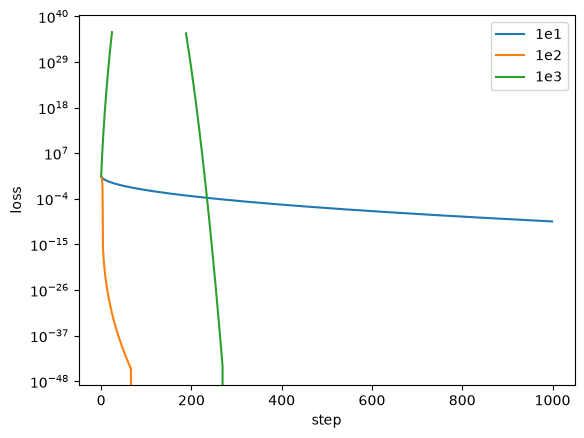

In [5]:
plt.plot(losses[1e1], label="1e1")
plt.plot(losses[1e2], label="1e2")
plt.plot(losses[1e3], label="1e3")
plt.yscale("log")
plt.ylabel("loss")
plt.xlabel("step")
plt.legend()
plt.show()